# Autonomous Control: Balancing a Cart-Pole with a Heuristic and PPO

**Family:** End-to-end project | **Dataset:** `CartPole-v1` | **Task:** control

Compare a hand written controller, a random policy and PPO, then test robustness to noise.

## Table of Contents

- 1. Problem statement
- 2. Business or research context
- 3. Dataset documentation
- 4. Research references
- 5. Exploratory analysis
- 6. Preprocessing
- 7. Model selection
- 8. Model training
- 9. Evaluation
- 10. Comparison
- 11. Interpretation
- 12. Limitations
- 13. Final recommendations

## 1. Problem statement

Keep a pole balanced on a cart for 500 steps, and find out how robust each controller is to sensor and actuator noise.

## 2. Business or research context

Learned controllers are only useful if they beat a simple engineered baseline and survive realistic noise. We test three controllers on the same evaluation seeds. This is a simulation, not a real vehicle.

## 3. Dataset documentation

**CartPole-v1** (Gymnasium classic control), simulated. 4 state values, 2 actions, reward 1 per step, maximum return 500. There is no dataset and no licence issue for the data. Gymnasium is MIT licensed.

## 4. Research references

Verification status is from the build environment on 2026-11-17. Entries marked *not verified* must be checked before citing.

- Schulman, J., Wolski, F., Dhariwal, P., Radford, A. and Klimov, O. (2017). *Proximal Policy Optimization Algorithms*. arXiv:1707.06347. https://arxiv.org/abs/1707.06347 Verification: arXiv abstract page 2026-11-17
- Towers, M. et al. (2024). *Gymnasium: A Standard Interface for Reinforcement Learning Environments*. arXiv:2407.17032. https://arxiv.org/abs/2407.17032 Verification: arXiv abstract page 2026-11-17
- Henderson, P. et al. (2018). *Deep Reinforcement Learning that Matters*. AAAI 2018; arXiv:1709.06560. https://arxiv.org/abs/1709.06560 Verification: arXiv abstract page 2026-11-17

PPO (Schulman et al.), the environment API (Towers et al.) and a warning about seeds and reporting (Henderson et al.).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline, build_preprocessor
from ml_lab.evaluation import evaluate_estimator, internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
PROJECT_ID = "autonomous_control"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
import gymnasium as gym
from ml_lab.rl import deep
from ml_lab.evaluation import evaluate_policy
make_env = lambda: gym.make("CartPole-v1")
print(make_env().observation_space, make_env().action_space)

Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32) Discrete(2)


## 5. Exploratory analysis

Behaviour of a random policy and of the simple heuristic on 30 episodes.

In [3]:
rng = np.random.default_rng(0)
random_policy = lambda s: int(rng.integers(2))
heuristic = lambda s: int(s[2] + 0.5 * s[3] > 0)            # push toward the lean
for name, pol in [("random", random_policy), ("heuristic", heuristic)]:
    r = evaluate_policy(make_env, pol, episodes=30, seed=2000)
    print(name, {k: round(v, 1) for k, v in r.items()})

random {'mean_return': 23.4, 'median_return': 19.5, 'std_return': 12.0, 'mean_length': 23.4}


heuristic {'mean_return': 500.0, 'median_return': 500.0, 'std_return': 0.0, 'mean_length': 500.0}


## 6. Preprocessing

No data preparation. Training seeds are 0, 1 and 2 with 40 960 steps each. Evaluation uses 30 episodes with environment seeds from 5000 that training never used. Noise is added to observations (Gaussian) or to actions (random flip).

In [4]:
SEEDS = [0, 1, 2]
def noisy(policy, obs_std=0.0, flip=0.0, seed=0):
    r = np.random.default_rng(seed)
    def wrapped(s):
        s = np.asarray(s) + r.normal(0, obs_std, size=len(s)) if obs_std else s
        a = policy(s)
        return int(1 - a) if r.random() < flip else a
    return wrapped

## 7. Model selection

Controllers: random, hand written heuristic, PPO from `ml_lab.rl`. No search over controllers is done, so there is no selection on test data.

In [5]:
print("PPO config: rollout 1024, 10 epochs, minibatch 128, lr 1e-3, clip 0.2, gamma 0.99, lambda 0.95")

PPO config: rollout 1024, 10 epochs, minibatch 128, lr 1e-3, clip 0.2, gamma 0.99, lambda 0.95


## 8. Model training

Train PPO with three seeds.

In [6]:
runs = {s: deep.train_ppo(seed=s, total_steps=40960) for s in SEEDS}
for s in SEEDS:
    print("seed", s, "| last 10 training episodes:", round(float(np.mean(runs[s]["returns"][-10:])), 1))

seed 0 | last 10 training episodes: 500.0
seed 1 | last 10 training episodes: 500.0
seed 2 | last 10 training episodes: 479.2


## 9. Evaluation

Return over 30 evaluation episodes per condition. PPO is evaluated per seed and averaged over the three seeds.

In [7]:
conds = {"clean": dict(), "observation noise 0.05": dict(obs_std=0.05), "observation noise 0.1": dict(obs_std=0.1), "action flip 10%": dict(flip=0.1)}
table = {}
for cname, kw in conds.items():
    row = {}
    row["random"] = evaluate_policy(make_env, noisy(random_policy, seed=1, **kw), episodes=30, seed=5000)["mean_return"]
    row["heuristic"] = evaluate_policy(make_env, noisy(heuristic, seed=1, **kw), episodes=30, seed=5000)["mean_return"]
    ppo = [evaluate_policy(make_env, noisy(runs[s]["policy"], seed=1, **kw), episodes=30, seed=5000)["mean_return"] for s in SEEDS]
    row["ppo_mean"], row["ppo_std_across_seeds"] = float(np.mean(ppo)), float(np.std(ppo, ddof=1))
    table[cname] = row
res = pd.DataFrame(table).T
display(res.round(1))
METRICS = {f"{c.replace(' ', '_').replace('%', 'pct')}_{k}": float(v) for c, row in table.items() for k, v in row.items()}
CONFIG = {"algorithm": "PPO", "total_steps": 40960, "seeds": 3, "eval_episodes": 30}
EXTRA = {"table": res.round(2).reset_index().to_dict("records")}
ALGORITHM = "PPO"

record = ExperimentRecord(notebook=PROJECT_ID, family="project", algorithm=ALGORITHM, dataset="CartPole-v1", task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,random,heuristic,ppo_mean,ppo_std_across_seeds
clean,21.0,500.0,496.6,5.9
observation noise 0.05,23.9,436.8,500.0,0.0
observation noise 0.1,22.2,343.8,499.2,1.3
action flip 10%,24.4,411.5,497.7,4.0


saved: /home/claude/open-python/experiments/results/autonomous_control.json


,metric
clean_random,21.0333
clean_heuristic,500.0000
clean_ppo_mean,496.6000
clean_ppo_std_across_seeds,5.8890
observation_noise_0.05_random,23.9333
observation_noise_0.05_heuristic,436.8000
observation_noise_0.05_ppo_mean,500.0000
observation_noise_0.05_ppo_std_across_seeds,0.0000
observation_noise_0.1_random,22.2000
observation_noise_0.1_heuristic,343.8333


## 10. Comparison

The table above is the comparison. The plot shows returns per condition.

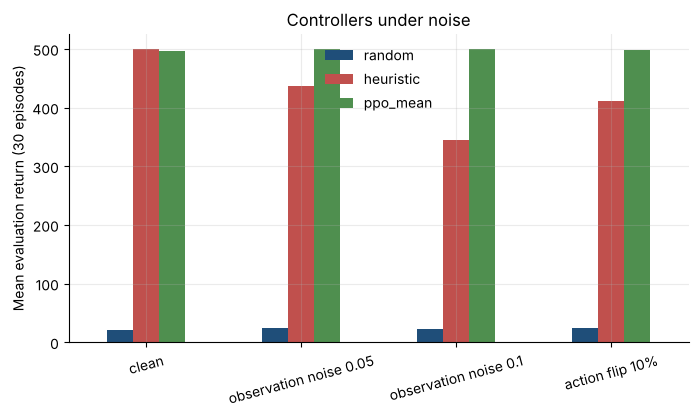

In [8]:
ax = res[["random", "heuristic", "ppo_mean"]].plot.bar(figsize=(8, 4), rot=15)
ax.set_ylabel("Mean evaluation return (30 episodes)"); ax.set_title("Controllers under noise"); save_figure(ax.figure, PROJECT_ID, "robustness"); plt.show()

## 11. Interpretation

Compare the drop in return from the clean condition to each noisy condition.

In [9]:
drop = res[["heuristic", "ppo_mean"]].rsub(res.loc["clean", ["heuristic", "ppo_mean"]], axis=1)
display(drop.round(1).rename(columns={"heuristic": "heuristic drop", "ppo_mean": "PPO drop"}))

,heuristic drop,PPO drop
clean,0.0,0.0
observation noise 0.05,63.2,-3.4
observation noise 0.1,156.2,-2.6
action flip 10%,88.5,-1.1


## 12. Limitations

Three seeds and a small training budget. A simple heuristic may beat PPO or not. The table shows which on this setup. The simulator is noise free by default and real systems have delay, friction and sensor faults that are not modelled.

## 13. Final recommendations

Never deploy a learned controller without an engineered baseline and a noise test. For a real system add safety limits, more seeds with intervals, and tests on a higher fidelity simulator.